# MLT Assignment #1.

Nedorezov Danil 
Big Data And ML

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, log_loss,
    precision_recall_curve, roc_curve, roc_auc_score, average_precision_score,
    confusion_matrix,
)

RANDOM_STATE = 1
plt.rcParams["figure.figsize"] = (7, 5)
%matplotlib inline

## 1. Data

In [2]:
bioresponse = pd.read_csv("data/bioresponse.csv", header=0, sep=",")
print(bioresponse.shape)
bioresponse.head()

(3751, 1777)


,Activity,D1,D2,D3,D4,D5,D6,D7,D8,D9,...,D1767,D1768,D1769,D1770,D1771,D1772,D1773,D1774,D1775,D1776
0,1,0.000000,0.497009,0.10,0.0,0.132956,0.678031,0.273166,0.585445,0.743663,...,0,0,0,0,0,0,0,0,0,0
1,1,0.366667,0.606291,0.05,0.0,0.111209,0.803455,0.106105,0.411754,0.836582,...,1,1,1,1,0,1,0,0,1,0
2,1,0.033300,0.480124,0.00,0.0,0.209791,0.610350,0.356453,0.517720,0.679051,...,0,0,0,0,0,0,0,0,0,0
3,1,0.000000,0.538825,0.00,0.5,0.196344,0.724230,0.235606,0.288764,0.805110,...,0,0,0,0,0,0,0,0,0,0
4,0,0.100000,0.517794,0.00,0.0,0.494734,0.781422,0.154361,0.303809,0.812646,...,0,0,0,0,0,0,0,0,0,0


In [3]:
target = bioresponse["Activity"].values
data = bioresponse.iloc[:, 1:]

print("bioresponse = 1: {:.2f}".format(target.mean()))
print("bioresponse = 0: {:.2f}".format(1 - target.mean()))
print("missing values:", bioresponse.isna().sum().sum())

bioresponse = 1: 0.54
bioresponse = 0: 0.46
missing values: 0


The classes are balanced, there are no missing values and the features are already normalized,
so no preprocessing is required.

## 2. Train / test split, 75% / 25%

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    data, target, test_size=0.25, stratify=target, random_state=RANDOM_STATE
)
print("train:", X_train.shape, "test:", X_test.shape)
print("share of class 1: train = {:.3f}, test = {:.3f}".format(y_train.mean(), y_test.mean()))

train: (2813, 1776) test: (938, 1776)
share of class 1: train = 0.542, test = 0.543


## 3. Training the four classifier

In [5]:
models = {
    "Small tree": DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
    "Deep tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Forest on small trees": RandomForestClassifier(
        n_estimators=100, max_depth=3, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Forest on deep trees": RandomForestClassifier(
        n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1
    ),
}

proba = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    proba[name] = model.predict_proba(X_test)[:, 1]
    depth = model.get_depth() if hasattr(model, "get_depth") else max(t.get_depth() for t in model.estimators_)
    print(f"{name:<24} trained, depth = {depth}")

Small tree               trained, depth = 3


Deep tree                trained, depth = 38
Forest on small trees    trained, depth = 3


Forest on deep trees     trained, depth = 34


## 4. Quality metrics

Precision, recall, accuracy and F1 are computed after binarizing the predicted probabilities with the
threshold $T = 0.5$; log-loss is computed directly from the probabilities.

In [6]:
def evaluate(y_true, p, threshold=0.5):
    y_pred = (p >= threshold).astype(int)
    return {
        "precision": precision_score(y_true, y_pred),
        "recall": recall_score(y_true, y_pred),
        "accuracy": accuracy_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
        "log_loss": log_loss(y_true, np.clip(p, 1e-15, 1 - 1e-15)),
    }


results = pd.DataFrame({name: evaluate(y_test, p) for name, p in proba.items()}).T
results.round(3)

,precision,recall,accuracy,f1,log_loss
Small tree,0.752,0.780,0.741,0.766,0.591
Deep tree,0.758,0.776,0.744,0.767,8.837
Forest on small trees,0.721,0.798,0.723,0.757,0.598
Forest on deep trees,0.784,0.829,0.784,0.806,0.467



## 5. Precision-recall and ROC curves

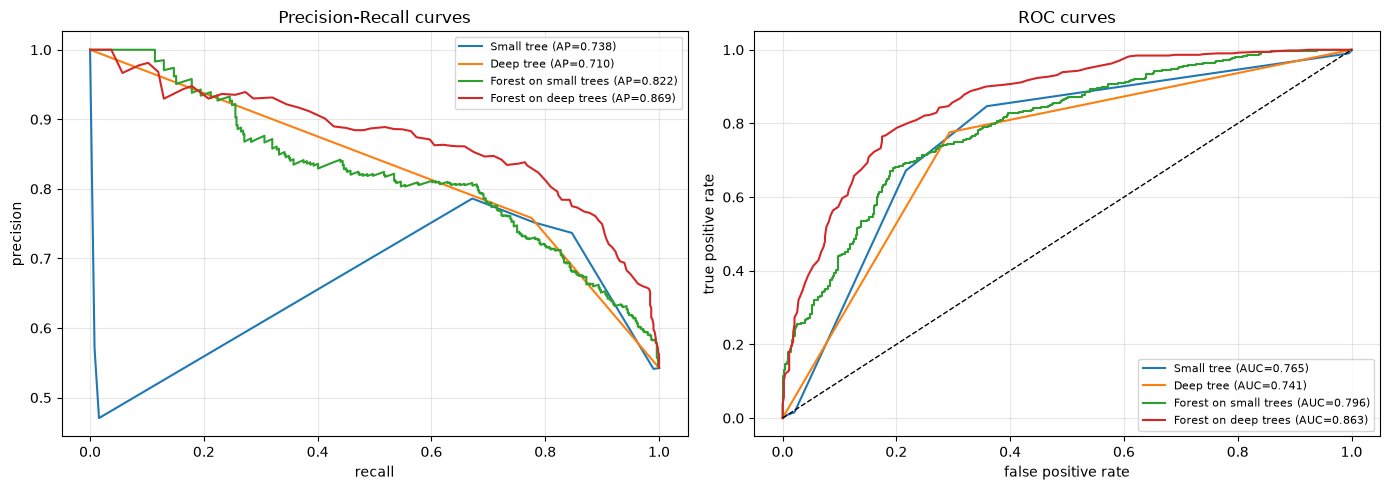

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

for name, p in proba.items():
    precision, recall, _ = precision_recall_curve(y_test, p)
    ax[0].plot(recall, precision, label=f"{name} (AP={average_precision_score(y_test, p):.3f})")
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[1].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, p):.3f})")

ax[0].set_xlabel("recall")
ax[0].set_ylabel("precision")
ax[0].set_title("Precision-Recall curves")
ax[0].legend(fontsize=8)
ax[0].grid(alpha=0.3)

ax[1].plot([0, 1], [0, 1], "k--", lw=1)
ax[1].set_xlabel("false positive rate")
ax[1].set_ylabel("true positive rate")
ax[1].set_title("ROC curves")
ax[1].legend(fontsize=8)
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 6. A classifier that avoids Type II errors


In [8]:
best = "Forest on deep trees"

clf_fn = RandomForestClassifier(
    n_estimators=100, class_weight={0: 1, 1: 5}, random_state=RANDOM_STATE, n_jobs=-1
)
clf_fn.fit(X_train, y_train)
p_fn = clf_fn.predict_proba(X_test)[:, 1]

precision, recall, thresholds = precision_recall_curve(y_test, p_fn)
mask = recall[:-1] >= 0.955
T_fn = thresholds[mask][np.argmax(precision[:-1][mask])]
print(f"selected threshold T = {T_fn:.3f}")

selected threshold T = 0.540


In [9]:
metrics_fn = evaluate(y_test, p_fn, T_fn)

comparison = pd.DataFrame({
    "Forest on deep trees, T=0.5": evaluate(y_test, proba[best], 0.5),
    f"Avoids Fn, T={T_fn:.2f}": metrics_fn,
}).T
comparison.round(3)

,precision,recall,accuracy,f1,log_loss
"Forest on deep trees, T=0.5",0.784,0.829,0.784,0.806,0.467
"Avoids Fn, T=0.54",0.676,0.961,0.729,0.794,0.628


In [10]:
print(f"recall = {metrics_fn['recall']:.4f}")
print("requirement recall > 0.95:", "SATISFIED" if metrics_fn["recall"] > 0.95 else "NOT SATISFIED")

for name, p_, t in [("baseline", proba[best], 0.5), ("avoids Fn", p_fn, T_fn)]:
    tn, fp, fn, tp = confusion_matrix(y_test, (p_ >= t).astype(int)).ravel()
    print(f"{name:<10} Tp={tp:4d}  Tn={tn:4d}  Fp={fp:4d}  Fn={fn:4d}  recall={tp / (tp + fn):.3f}")

recall = 0.9607
requirement recall > 0.95: SATISFIED
baseline   Tp= 422  Tn= 313  Fp= 116  Fn=  87  recall=0.829
avoids Fn  Tp= 489  Tn= 195  Fp= 234  Fn=  20  recall=0.961


The number of Fn errors drops several times over and recall rises above the required 0.95, at the cost of
more Fp errors and a lower precision. Accuracy goes down as well: it penalizes both kinds of errors equally and
is therefore a poor objective whenever their costs are asymmetric.